In [1]:
import joblib
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Đánh giá
from sklearn.metrics import (
    classification_report, 
    f1_score, 
    recall_score, 
    precision_score, 
    roc_auc_score, 
    average_precision_score,
    precision_recall_curve,
    confusion_matrix
)

# Đường dẫn đến thư mục chứa dữ liệu đã xử lý
DATA_PATH = r"C:/Users/Tien Cong/OneDrive - National Economics University/Statistical learning (ML)/data/processed"

In [2]:
def load_data(path):
    X_train = joblib.load(os.path.join(path, 'X_train.pkl'))
    y_train = joblib.load(os.path.join(path, 'y_train.pkl'))
    X_test = joblib.load(os.path.join(path, 'X_test.pkl'))
    y_test = joblib.load(os.path.join(path, 'y_test.pkl'))
    feature_cols = joblib.load(os.path.join(path, 'feature_cols.pkl'))
    return X_train, y_train, X_test, y_test, feature_cols

X_train, y_train, X_test, y_test, feature_cols = load_data(DATA_PATH)
print(f"Dữ liệu huấn luyện: {X_train.shape}")
print(f"Dữ liệu kiểm tra: {X_test.shape}")
print(f"\nPhân phối nhãn tập train:")
print(pd.Series(y_train).value_counts())
print(f"\nPhân phối nhãn tập test:")
print(pd.Series(y_test).value_counts())

Dữ liệu huấn luyện: (475714, 28)
Dữ liệu kiểm tra: (118929, 28)

Phân phối nhãn tập train:
0    469794
1      5920
Name: count, dtype: int64

Phân phối nhãn tập test:
0    117649
1      1280
Name: count, dtype: int64


## 1. Huấn luyện Balanced Random Forest Classifier

`BalancedRandomForestClassifier` từ thư viện `imbalanced-learn` xử lý mất cân bằng lớp bằng cách **random under-sampling** trên lớp đa số trong mỗi bootstrap sample khi xây dựng từng cây quyết định — không cần dùng SMOTE.

In [3]:
from imblearn.ensemble import BalancedRandomForestClassifier
# Khởi tạo model
brf = BalancedRandomForestClassifier(
    n_estimators=200,          # Số cây trong rừng
    max_depth=None,            # Không giới hạn độ sâu (để cây phát triển đầy đủ)
    min_samples_split=2,       # Số mẫu tối thiểu để tách nút
    min_samples_leaf=1,        # Số mẫu tối thiểu ở lá
    max_features='sqrt',       # Số đặc trưng xem xét mỗi lần tách (sqrt(n_features))
    sampling_strategy='auto',  # Tự động cân bằng: undersample lớp đa số về bằng lớp thiểu số
    replacement=False,         # Sampling không hoàn lại
    bootstrap=True,            # Dùng bootstrap sampling
    random_state=42,
    n_jobs=-1                  # Dùng toàn bộ CPU
)

print("Đang huấn luyện Balanced Random Forest Classifier...")
brf.fit(X_train, y_train)
print("Huấn luyện hoàn tất!")

Đang huấn luyện Balanced Random Forest Classifier...
Huấn luyện hoàn tất!


## 2. Dự đoán

In [4]:
# Dự đoán nhãn và xác suất
y_pred = brf.predict(X_test)
y_prob = brf.predict_proba(X_test)[:, 1]  # Xác suất của lớp dương (1)

print(f"Số mẫu dự đoán là lớp 1 (positive): {y_pred.sum()}")
print(f"Số mẫu thực tế là lớp 1 (positive): {y_test.sum()}")

Số mẫu dự đoán là lớp 1 (positive): 3075
Số mẫu thực tế là lớp 1 (positive): 1280


## 3. Đánh giá mô hình

In [5]:
# ── Các chỉ số chính ──────────────────────────────────────────────────────────
precision  = precision_score(y_test, y_pred, zero_division=0)
recall     = recall_score(y_test, y_pred, zero_division=0)
f1         = f1_score(y_test, y_pred, zero_division=0)
roc_auc    = roc_auc_score(y_test, y_prob)
pr_auc     = average_precision_score(y_test, y_prob)   # AUC của Precision-Recall curve

print("=" * 50)
print("        KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH")
print("=" * 50)
print(f"  Precision      : {precision:.4f}")
print(f"  Recall         : {recall:.4f}")
print(f"  F1-Score       : {f1:.4f}")
print(f"  ROC-AUC        : {roc_auc:.4f}")
print(f"  PR-AUC         : {pr_auc:.4f}")
print("=" * 50)

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

        KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH
  Precision      : 0.4130
  Recall         : 0.9922
  F1-Score       : 0.5832
  ROC-AUC        : 0.9985
  PR-AUC         : 0.8871

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.98      0.99    117649
           1       0.41      0.99      0.58      1280

    accuracy                           0.98    118929
   macro avg       0.71      0.99      0.79    118929
weighted avg       0.99      0.98      0.99    118929



## 4. Confusion Matrix

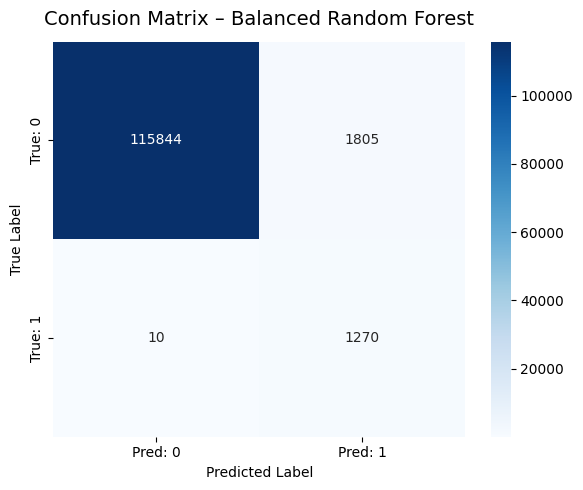

True Negatives  (TN): 115844
False Positives (FP): 1805
False Negatives (FN): 10
True Positives  (TP): 1270


In [6]:
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=['Pred: 0', 'Pred: 1'],
    yticklabels=['True: 0', 'True: 1'],
    ax=ax
)
ax.set_title('Confusion Matrix – Balanced Random Forest', fontsize=14, pad=12)
ax.set_xlabel('Predicted Label')
ax.set_ylabel('True Label')
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"True Negatives  (TN): {tn}")
print(f"False Positives (FP): {fp}")
print(f"False Negatives (FN): {fn}")
print(f"True Positives  (TP): {tp}")

## 5. Precision-Recall Curve

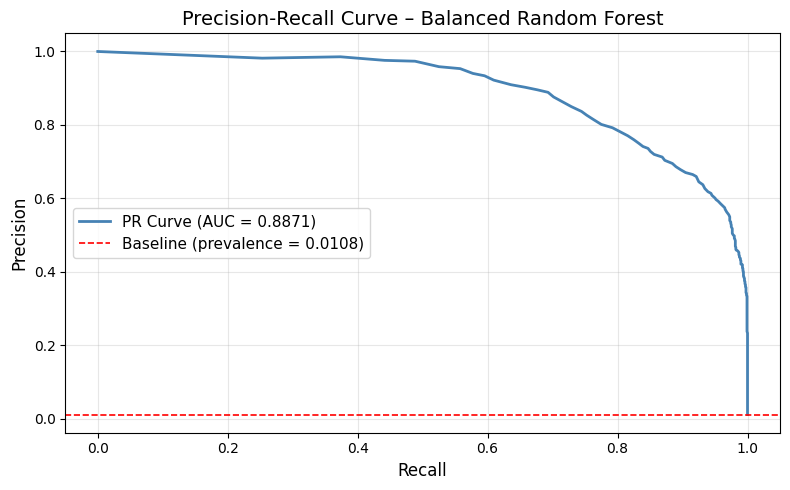

In [7]:
precisions, recalls, thresholds = precision_recall_curve(y_test, y_prob)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(recalls, precisions, color='steelblue', lw=2,
        label=f'PR Curve (AUC = {pr_auc:.4f})')
ax.axhline(y=y_test.mean(), color='red', linestyle='--', lw=1.2,
           label=f'Baseline (prevalence = {y_test.mean():.4f})')
ax.set_xlabel('Recall', fontsize=12)
ax.set_ylabel('Precision', fontsize=12)
ax.set_title('Precision-Recall Curve – Balanced Random Forest', fontsize=14)
ax.legend(fontsize=11)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Feature Importance

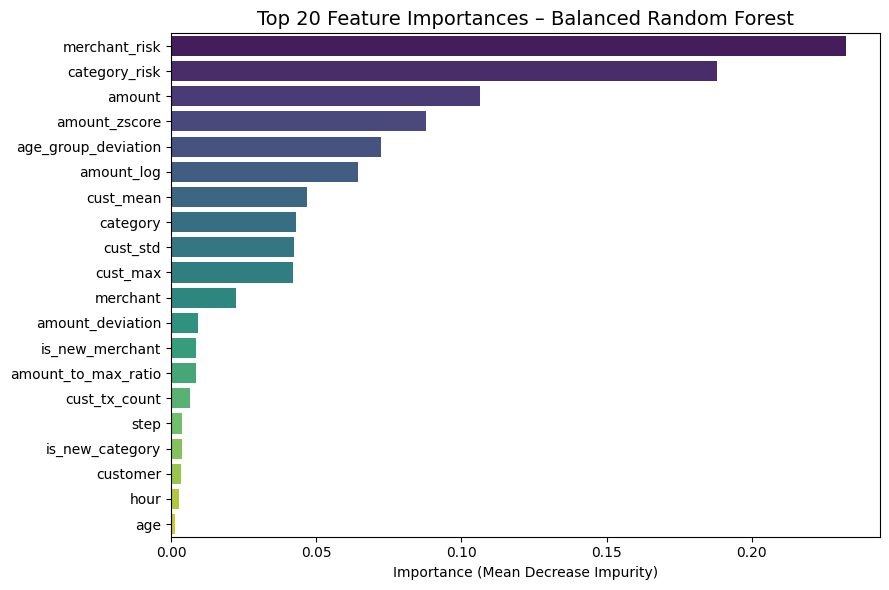


Top 20 features quan trọng nhất:
            feature  importance
      merchant_risk    0.232490
      category_risk    0.187946
             amount    0.106347
      amount_zscore    0.087693
age_group_deviation    0.072178
         amount_log    0.064425
          cust_mean    0.046750
           category    0.043204
           cust_std    0.042520
           cust_max    0.042016
           merchant    0.022398
   amount_deviation    0.009177
    is_new_merchant    0.008704
amount_to_max_ratio    0.008501
      cust_tx_count    0.006643
               step    0.003791
    is_new_category    0.003737
           customer    0.003620
               hour    0.002649
                age    0.001309


In [8]:
# Lấy feature importance và sắp xếp giảm dần
importance_df = pd.DataFrame({
    'feature':   feature_cols,
    'importance': brf.feature_importances_
}).sort_values('importance', ascending=False).reset_index(drop=True)

top_n = 20
top_df = importance_df.head(top_n)

fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(
    data=top_df, x='importance', y='feature',
    hue='feature', palette='viridis', legend=False, ax=ax
)
ax.set_title(f'Top {top_n} Feature Importances – Balanced Random Forest', fontsize=14)
ax.set_xlabel('Importance (Mean Decrease Impurity)')
ax.set_ylabel('')
plt.tight_layout()
plt.show()

print(f"\nTop {top_n} features quan trọng nhất:")
print(top_df.to_string(index=False))

## 7. Lưu mô hình

In [9]:
MODEL_SAVE_PATH = os.path.join(DATA_PATH, '..', 'models', 'brf_model.pkl')
os.makedirs(os.path.dirname(MODEL_SAVE_PATH), exist_ok=True)
joblib.dump(brf, MODEL_SAVE_PATH)
print(f"Mô hình đã được lưu tại: {os.path.abspath(MODEL_SAVE_PATH)}")

Mô hình đã được lưu tại: C:\Users\Tien Cong\OneDrive - National Economics University\Statistical learning (ML)\data\models\brf_model.pkl
